In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os
import xarray as xr
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import pandas as pd
import warnings
from xarray.coding.times import SerializationWarning
import cftime
from scipy.optimize import curve_fit
import importlib
from mpl_toolkits.axes_grid1.inset_locator import inset_axes, mark_inset
import matplotlib.patches as patches
import matplotlib.colors as colors
import matplotlib.cm as cm


# my own functions
import Functions
importlib.reload(Functions)
from Functions import *

### Opening and slicing data

#### Retreiving filepaths

In [7]:
EC_earth_dir = '/nobackup/users/hartevel/data/EC_earth/data'
UKESM_dir = '/nobackup/users/hartevel/data/UKESM/data/ukesm'
CNRM_dir_monthly = '/nobackup/users/hartevel/data/CNRM/CNRM'

# reanalysis data montly
ERA5_dir = '/nobackup/users/hartevel/data/ERA5/monthlymean/monthlymeans.nc'
JRA_dir = '/nobackup/users/hartevel/data/JRA3Q/monthlymean/monthlymeans.nc'
MERRA_dir = '/nobackup/users/hartevel/data/MERRA2/monthlymean/monthlymeans.nc'
RACMO_dir = '/nobackup/users/hartevel/data/RACMO'

# reanalysis data daily
ERA5_dayly_dir = '/nobackup_1/users/romijn/data/era5/era5/era5_combi_time_mean_daily_year'
ERA5_dayly_files = [ERA5_dayly_dir + '/' + f for f in os.listdir(ERA5_dayly_dir) if f.endswith('.nc')]

JRA_dayly_dir = '/nobackup_1/users/romijn/data/jra3q/jra3q/jra3q_combi_time_mean_daily_year'
JRA_dayly_files = [JRA_dayly_dir + '/' +f for f in os.listdir(JRA_dayly_dir) if f.endswith('.nc')]

MERRA_dayly_dir = '/nobackup_1/users/romijn/data/merra2/merra2/merra2_combi_time_mean_daily_year'
MERRA_dayly_files = [MERRA_dayly_dir + '/' +f for f in os.listdir(MERRA_dayly_dir) if f.endswith('.nc')]

# data_pi = EC_earth_dir + '/pi_control_smhi'
# data_2K = EC_earth_dir + '/gwl2p0_knmi'
# data_4K = EC_earth_dir + '/gwl4p0_dmi'

# data_pi = UKESM_dir + '/pi_control_smhi'
# data_2K = UKESM_dir + '/gwl2p0_knmi'
# data_4K = UKESM_dir + '/gwl4p0_dmi'

data_pi = CNRM_dir_monthly + '/PI'
data_2K = CNRM_dir_monthly + '/GWL2'
data_4K = CNRM_dir_monthly + '/GWL4'

def files(data_scenario):
    file_tas = [f for f in os.listdir(data_scenario) if f.startswith('tas')][0]
    file_prsn = [f for f in os.listdir(data_scenario) if f.startswith('prsn')][0]
    file_pr = [f for f in os.listdir(data_scenario) if f.startswith('pr_')][0]
    file_snfr = [f for f in os.listdir(data_scenario) if f.startswith('snfr')][0]
    return file_tas, file_prsn, file_pr, file_snfr
    
def filepath(data_scenario):
    filepaths = []
    for file in files(data_scenario):
        filepaths.append(data_scenario + '/'+ file)
    return filepaths

# All filepaths 
file_tas_pi, file_prsn_pi, file_pr_pi, file_snfr_pi = filepath(data_pi)
file_tas_2K, file_prsn_2K, file_pr_2K, file_snfr_2K = filepath(data_2K)
file_tas_4K, file_prsn_4K, file_pr_4K, file_snfr_4K = filepath(data_4K)


#### Opening and slicing data

In [8]:
warnings.simplefilter("ignore", SerializationWarning) # suppresses the warning that datetime does not work


def drop_duplicate_time(da, name="", verbose=True):
    """
    Remove duplicated time coordinates from a DataArray.
    Keeps the FIRST occurrence.
    """
    time = da.time

    # Boolean mask: True where time is NOT duplicated
    _, index = np.unique(time.values, return_index=True)
    index = np.sort(index)

    if verbose and len(index) < len(time):
        print(
            f"[INFO] Dropped {len(time) - len(index)} duplicate time steps from {name}"
        )

    return da.isel(time=index)


def load_and_align(tas_file, pr_file, prsn_file, verbose=True):
    tas  = xr.open_dataset(tas_file)['tas']
    pr   = xr.open_dataset(pr_file)['pr']
    prsn = xr.open_dataset(prsn_file)['prsn']

    # Remove duplicated time steps (before alignment!)
    tas  = drop_duplicate_time(tas,  name="tas",  verbose=verbose)
    pr   = drop_duplicate_time(pr,   name="pr",   verbose=verbose)
    prsn = drop_duplicate_time(prsn, name="prsn", verbose=verbose)

    # Align: keep only times present in ALL variables
    tas, pr, prsn = xr.align(tas, pr, prsn, join="inner")

    return tas, pr, prsn


tas_pi,  pr_pi,  prsn_pi  = load_and_align(file_tas_pi,  file_pr_pi,  file_prsn_pi)
tas_2K,  pr_2K,  prsn_2K  = load_and_align(file_tas_2K,  file_pr_2K,  file_prsn_2K)
tas_4K,  pr_4K,  prsn_4K  = load_and_align(file_tas_4K,  file_pr_4K,  file_prsn_4K)

[INFO] Dropped 12 duplicate time steps from tas
[INFO] Dropped 12 duplicate time steps from pr
[INFO] Dropped 12 duplicate time steps from prsn
[INFO] Dropped 12 duplicate time steps from tas
[INFO] Dropped 12 duplicate time steps from pr
[INFO] Dropped 12 duplicate time steps from prsn
[INFO] Dropped 12 duplicate time steps from tas
[INFO] Dropped 12 duplicate time steps from pr
[INFO] Dropped 12 duplicate time steps from prsn


In [11]:

data_len = min(len(tas_pi.time), 
               len(tas_2K.time), 
               len(tas_4K.time)) 

print(data_len)

# opening PI
# These xarrays use cftime instead of Datetime
tas_pi = tas_pi.isel(time = slice(0,data_len))
pr_pi = pr_pi.isel(time = slice(0,data_len))
prsn_pi = prsn_pi.isel(time = slice(0,data_len))
snfr_pi = xr.open_dataset(file_snfr_pi)['snfr'].isel(time = slice(0,data_len))

# opeing + 2K
tas_2K = tas_2K.isel(time = slice(0,data_len))
pr_2K = pr_2K.isel(time = slice(0,data_len))
prsn_2K = prsn_2K.isel(time = slice(0,data_len))
snfr_2K = xr.open_dataset(file_snfr_2K)['snfr'].isel(time = slice(0,data_len))

# opening + 4K
# These xarrays use cftime instead of Datetime
tas_4K = tas_4K.isel(time = slice(0,data_len))
pr_4K = pr_4K.isel(time = slice(0,data_len))
prsn_4K = prsn_4K.isel(time = slice(0,data_len))
snfr_4K = xr.open_dataset(file_snfr_4K)['snfr'].isel(time = slice(0,data_len))


2604


In [114]:
# snfr_pi = snow_fraction(prsn_pi, pr_pi)
# snfr_2K = snow_fraction(prsn_2K, pr_2K)
# snfr_4K = snow_fraction(prsn_4K, pr_4K)

-0.0004785657
0.0
0.0


In [19]:
ERA5_tas = ERA5_data.t2m
ERA5_pr = ERA5_data.mtpr
ERA5_prsn = ERA5_data.msr

JRA_tas = JRA_data['tmp2m-hgt-fc-gauss']
JRA_pr = JRA_data['tprate1have-sfc-fc-gauss']
JRA_prsn = JRA_data['tsrwe1have-sfc-fc-gauss']

MERRA_tas = MERRA_data.TLML
MERRA_pr = MERRA_data.PRECTOT 
MERRA_prsn = MERRA_data.PRECSNO

RACMO_tas = xr.open_dataset([RACMO_dir + '/' + f for f in os.listdir(RACMO_dir) if f.startswith('tas')][0]).tas
RACMO_prsn = xr.open_dataset([RACMO_dir + '/' + f for f in os.listdir(RACMO_dir) if f.startswith('sf')][0]).sf
RACMO_pr = xr.open_dataset([RACMO_dir + '/' + f for f in os.listdir(RACMO_dir) if f.startswith('pr_')][0]).pr

#### Obtaining snow fraction reanalysis data

In [20]:
# ERA5_snfr = snow_fraction(ERA5_prsn, ERA5_pr) 
# JRA_snfr = snow_fraction(JRA_prsn, JRA_pr) 
# MERRA_snfr = snow_fraction(MERRA_prsn, MERRA_pr) 
RACMO_snfr = snow_fraction(RACMO_prsn, RACMO_pr)

-0.015533447


### Some functions

In [12]:
def snowfraction(T, a, b):
    T = T-273.15    # convert temperature from kelvin to celcius
    snfr = 1 / (1 + (a * (b**T)))
    return snfr

In [13]:
def tas_snfr_plot(tas_array, snfr_array, savename = 'quickplot.png', best_a = 'no_fit', best_b = 1):
    tas_1d = tas_array.stack(points=("time","lat","lon"))
    snfr_1d = snfr_array.stack(points=("time","lat", "lon"))   
    
    T = np.linspace(230,310,100)
    plt.figure()
    plt.scatter(tas_1d, snfr_1d, s=1, alpha = 0.01)

    if best_a != 'no_fit':
        plt.plot(T, snowfraction(T, np.mean(best_a), np.mean(best_b)), linewidth = 1.2, c = 'red', label = 'Best fit')
        plt.plot(T, snowfraction(T, 1.61, 1.35), linewidth = 1.2, c = 'orange', label = 'Krasting et al 2014')
        
    plt.xlabel("Near surface air temperature [K]")
    plt.ylabel("Snowfall fraction")
    plt.savefig(savename)
    plt.show()
    return


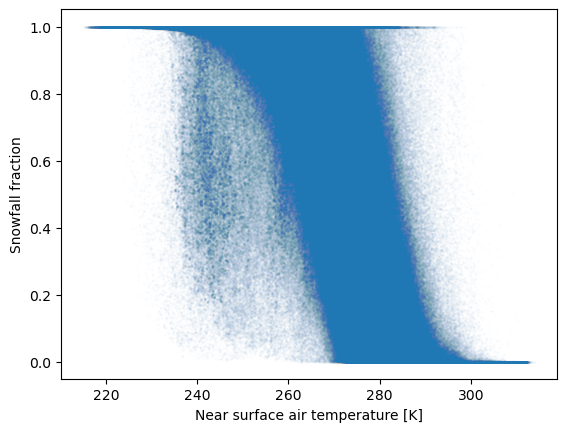

In [80]:
tas_snfr_plot(tas_pi, snfr_pi)

### Plotting raw data

#### Plotting RACMO

/tmp/ipykernel_4137698/1615390450.py:17: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig('quickplot.png')
/usr/people/hartevel/miniconda3/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


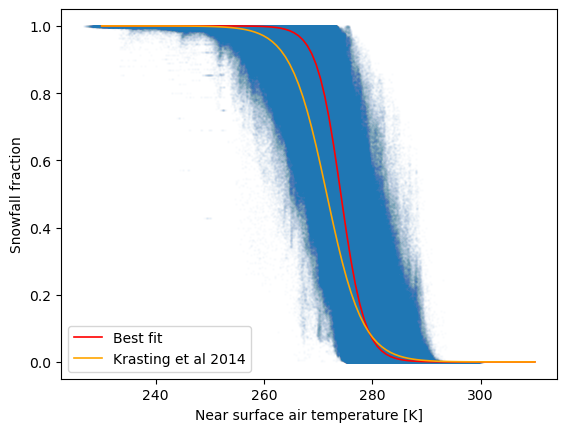

In [21]:
# tas_snfr_plot(MERRA_tas, MERRA_snfr, 'snowfraction_temp_MERRA.png' )

RACMO_tas_sliced = RACMO_tas.isel(time = slice(0,100)).isel(rlon = slice(0,300))
RACMO_snfr_sliced = RACMO_snfr.isel(time = slice(0,100)).isel(rlon = slice(0,300))

tas_1d_RACMO = RACMO_tas_sliced.stack(points=("time","rlat","rlon")).squeeze()
snfr_1d_RACMO = RACMO_snfr_sliced.stack(points=("time","rlat", "rlon")).squeeze() 

T = np.linspace(230,310,100)
plt.figure()
plt.scatter(tas_1d_RACMO, snfr_1d_RACMO, s=1, alpha = 0.01) 
plt.plot(T, snowfraction(T, 0.6332987332457405, 1.565550841094958), linewidth = 1.2, c = 'red', label = 'Best fit')
plt.plot(T, snowfraction(T, 1.61, 1.35), linewidth = 1.2, c = 'orange', label = 'Krasting et al 2014')
plt.xlabel("Near surface air temperature [K]")
plt.ylabel("Snowfall fraction")
plt.legend()
plt.savefig('quickplot.png')
plt.show()




#### PLotting raw reanalysis data

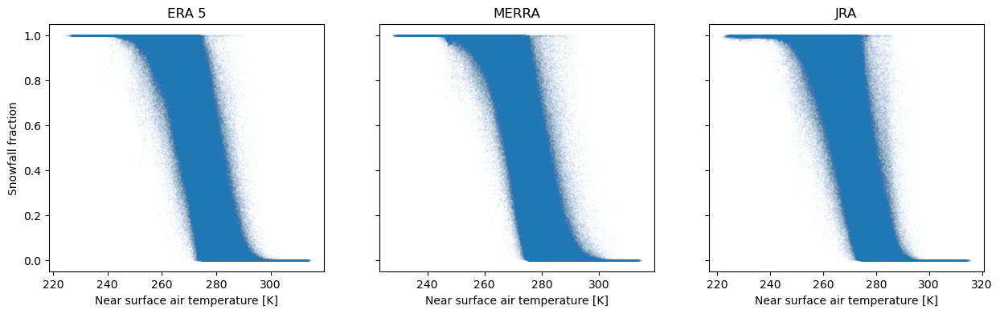

In [23]:


tas_1d_ERA5 = ERA5_tas.stack(points=("time","lat","lon"))
snfr_1d_ERA5 = ERA5_snfr.stack(points=("time","lat", "lon"))   
tas_1d_MERRA = MERRA_tas.stack(points=("time","lat","lon"))
snfr_1d_MERRA = MERRA_snfr.stack(points=("time","lat", "lon"))
tas_1d_JRA = JRA_tas.stack(points=("time","lat","lon"))
snfr_1d_JRA = JRA_snfr.stack(points=("time","lat", "lon"))

T = np.linspace(230,310,100)
fig, ax = plt.subplots(1,3, figsize = (15,4), sharey = True)
ax[0].scatter(tas_1d_ERA5, snfr_1d_ERA5, s=1, alpha = 0.01)
ax[0].set_ylabel("Snowfall fraction")
ax[0].set_xlabel("Near surface air temperature [K]")
ax[0].set_title('ERA 5')

ax[1].scatter(tas_1d_MERRA, snfr_1d_MERRA, s=1, alpha = 0.01)
ax[1].set_xlabel("Near surface air temperature [K]")
ax[1].set_title('MERRA')

ax[2].scatter(tas_1d_JRA, snfr_1d_JRA, s=1, alpha = 0.01)
ax[2].set_xlabel("Near surface air temperature [K]")
ax[2].set_title('JRA')
plt.savefig('snowfraction_temp_ERA5_MERRA_JRA.png')
plt.show()

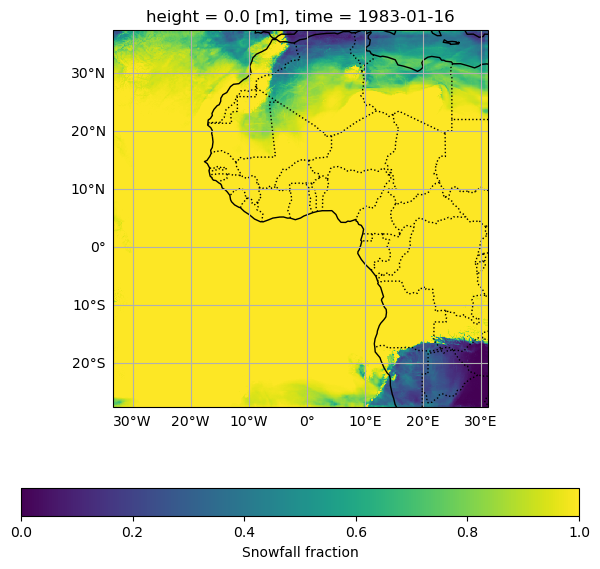

In [24]:
# snfr_2d = snfr_2K.sel(time=pd.to_datetime('2057-01-16 12:00:00'))
snfr_2d = RACMO_snfr.isel(time=36)

# # snfr_2d = snfr_2K.sel(time=pd.to_datetime('2057-01-16 12:00:00')) For if you want to see the snowfraction without seasons
# snfr_2d = Remove_SeasCyc(snfr_2K).isel(time=307)

# Create a figure and axis with a map projection
fig, ax = plt.subplots(figsize=(12, 7), subplot_kw={"projection": ccrs.PlateCarree()})

# Plot the data
snfr_2d.plot(
    ax=ax, 
    transform=ccrs.PlateCarree(),  # tells Cartopy that the data is lat/lon
    # vmin=-1.0,
    # vmax=1.0,
    cmap='viridis',              # color map
    cbar_kwargs={'label': 'Snowfall fraction', 'orientation': 'horizontal', 'shrink': 0.6}
)

# Add coastlines and borders
ax.coastlines()
ax.add_feature(cfeature.BORDERS, linestyle=':')

# Add gridlines
gl = ax.gridlines(draw_labels=True)
gl.top_labels = False
gl.right_labels = False

plt.savefig('snfr_at_time.png')

plt.show()

### Checking dayly data

-1.493483e-07
-4.57552e-08
-9.495125e-10


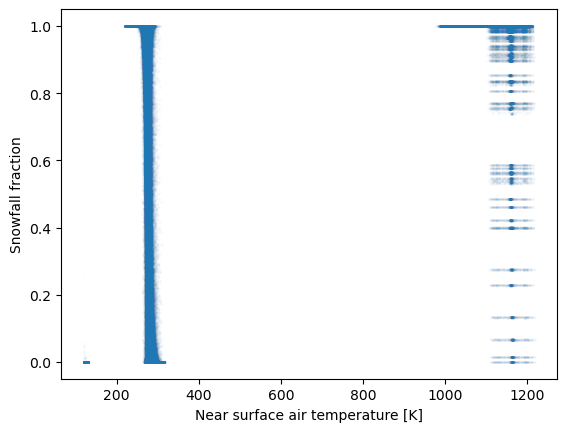

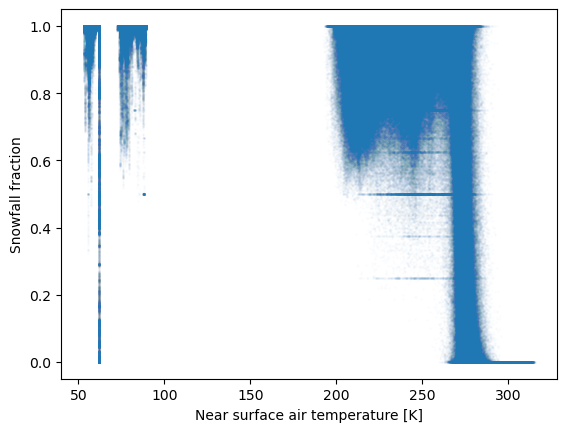

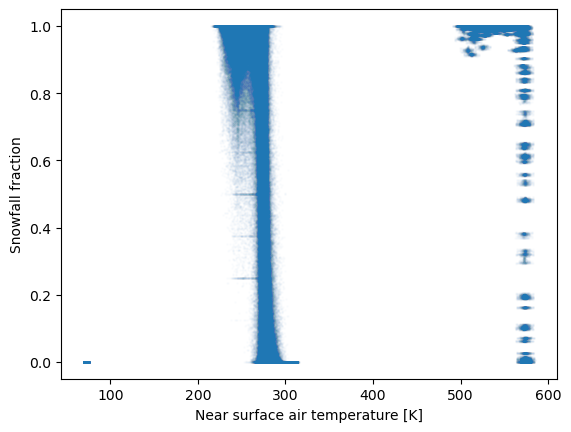

In [10]:
def check_dayly_data(year):
    ERA5_at_year = xr.open_dataset(ERA5_dayly_files[year]).rename(valid_time = 'time')#.sel(lat = slice(0,90))
    JRA_at_year = xr.open_dataset(JRA_dayly_files[year])#.sel(lat = slice(0,90))
    MERRA_at_year = xr.open_dataset(MERRA_dayly_files[year])#.sel(lat = slice(0,90))
    
    ERA5_tas_at_year = ERA5_at_year.t2m
    ERA5_pr_at_year = ERA5_at_year.mtpr
    ERA5_prsn_at_year = ERA5_at_year.msr
    
    JRA_tas_at_year = JRA_at_year['tmp2m-hgt-fc-gauss']
    JRA_pr_at_year = JRA_at_year['tprate1have-sfc-fc-gauss']
    JRA_prsn_at_year = JRA_at_year['tsrwe1have-sfc-fc-gauss']
    
    MERRA_tas_at_year = MERRA_at_year.TLML
    MERRA_pr_at_year = MERRA_at_year.PRECTOT 
    MERRA_prsn_at_year = MERRA_at_year.PRECSNO
    
    ERA5_snfr_at_year = snow_fraction(ERA5_prsn_at_year, ERA5_pr_at_year) 
    JRA_snfr_at_year = snow_fraction(JRA_prsn_at_year, JRA_pr_at_year) 
    MERRA_snfr_at_year = snow_fraction(MERRA_prsn_at_year, MERRA_pr_at_year) 
    
    tas_snfr_plot(MERRA_tas_at_year, MERRA_snfr_at_year, 'snowfraction_temp_MERRA.png' )
    tas_snfr_plot(JRA_tas_at_year, JRA_snfr_at_year, 'snowfraction_temp_JRA.png' )
    tas_snfr_plot(ERA5_tas_at_year, ERA5_snfr_at_year, 'snowfraction_temp_ERA5.png' )

check_dayly_data(9)


### Fitting

#### Examining the fitting function

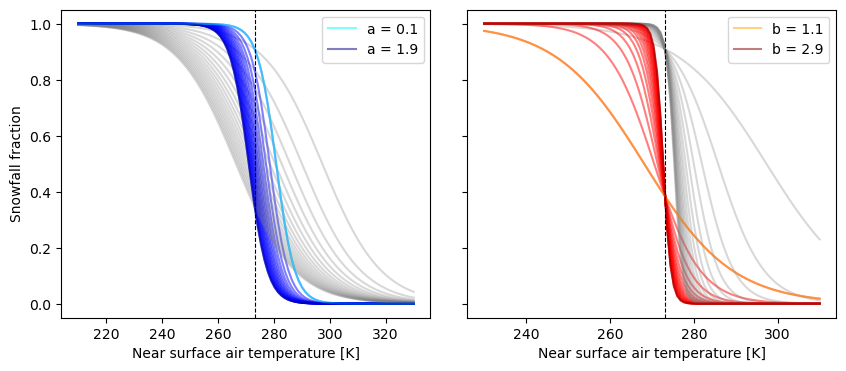

In [26]:
T1 = np.linspace(210,330,100)
T2 = np.linspace(230,310,100)
test_array = np.arange(0.1,2,0.1)

fig, ax = plt.subplots(1,2, figsize = (10,4), sharey = True)
for a in test_array:
    ax[0].plot(T1, snowfraction(T1, a, 1.1), alpha = 0.3, c = 'gray')
    ax[0].plot(T1, snowfraction(T1, a, 1.35), alpha = 0.5, c = 'blue')
    ax[1].plot(T2, snowfraction(T2, 0.1, a + 1), alpha = 0.3, c = 'gray')
    ax[1].plot(T2, snowfraction(T2, 1.61, a + 1), alpha = 0.5, c = 'red')

ax[0].plot(T1, snowfraction(T1, test_array[0], 1.35), alpha = 0.5, c = 'cyan', label = f'a = {test_array[0]}')
ax[0].plot(T1, snowfraction(T1, test_array[-1], 1.35), alpha = 0.5, c = 'navy', label = f'a = {round(test_array[-1],2)}')
ax[0].set_ylabel('Snowfall fraction')
ax[0].axvline(x = 273.15, c = 'black', linewidth = 0.8, linestyle = '--')
ax[0].set_xlabel('Near surface air temperature [K]')
ax[0].legend()
ax[1].plot(T2, snowfraction(T2, 1.61, test_array[0] + 1), alpha = 0.5, c = 'orange', label = f'b = {test_array[0]+1}')
ax[1].plot(T2, snowfraction(T2, 1.61, test_array[-1] + 1), alpha = 0.5, c = 'maroon', label = f'b = {round(test_array[-1]+1, 2)}')
ax[1].axvline(x = 273.15, c = 'black', linewidth = 0.8, linestyle = '--')
ax[1].legend()
ax[1].set_xlabel('Near surface air temperature [K]')

plt.subplots_adjust(wspace=0.1) 
plt.savefig('werking_a_en_b.png')
plt.show()

#### Actual fitting

In [10]:
def fitting_snfr_T(tas_array, snfr_array, timestamps_nr = 7, longitudes_nr = 37):
    a = []
    b = []
    mean_temp = []
    max_time = len(tas_array.time)
    timestamps = np.linspace(0,max_time,timestamps_nr, dtype = int)
    longtitudes = np.linspace(0,359,longitudes_nr, dtype = int)
    
    for t in range(len(timestamps)-1):
        print(timestamps[t])
        
        for i in range(len(longtitudes)-1):
                
            tas_1d = tas_array.sel(lon = slice(longtitudes[i],longtitudes[i+1])).isel(time = slice(timestamps[t], timestamps[t+1])).stack(points=("time","lat","lon"))
            snfr_1d = snfr_array.sel(lon = slice(longtitudes[i],longtitudes[i+1])).isel(time = slice(timestamps[t], timestamps[t+1])).stack(points=("time","lat", "lon"))

            mask = (~tas_1d.isnull()) & (~snfr_1d.isnull())
            
            tas_1d  = tas_1d.where(mask, drop=True).values
            snfr_1d = snfr_1d.where(mask, drop=True).values 

            # plt.figure()
            # plt.scatter(tas_1d, snfr_1d, s = 0.1)
            # plt.title(f'mean temp = {float(tas_1d.mean())}')
            # plt.show()

            # print(tas_1d)
            try:
                popt, pcov = curve_fit(snowfraction, tas_1d, snfr_1d)
            except RuntimeError:
                # curve_fit failed — skip this iteratiVoor on
                print("Fit failed for this iteration, skipping.")
                continue
        
            a.append(popt[0])
            b.append(popt[1])
            mean_temp.append(tas_1d.mean())

    return a, b, mean_temp

0


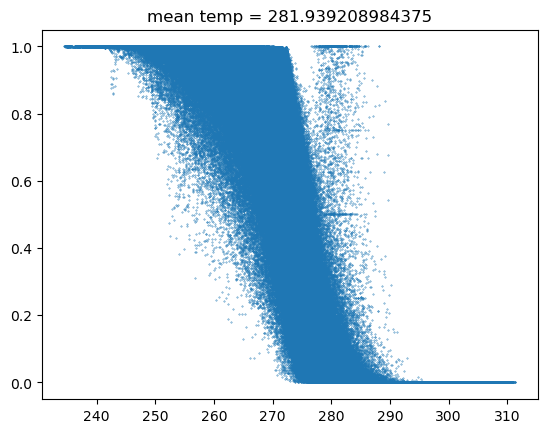

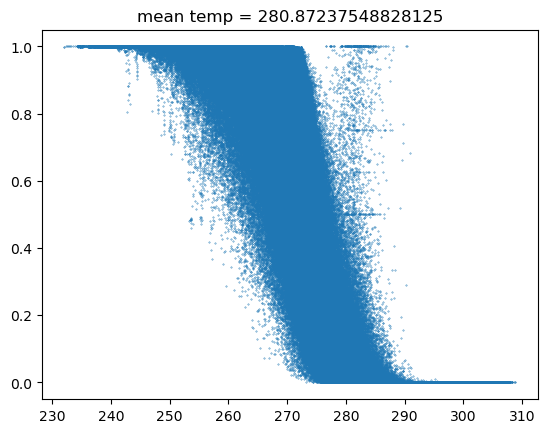

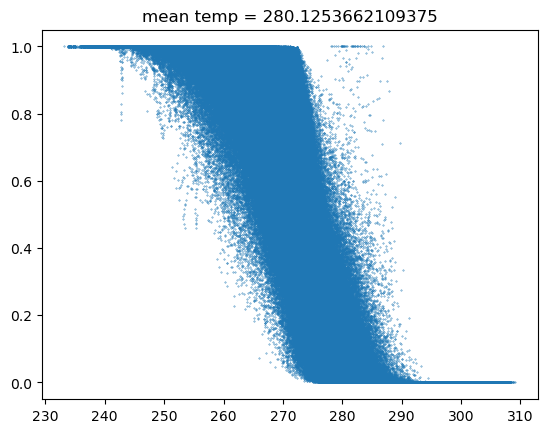

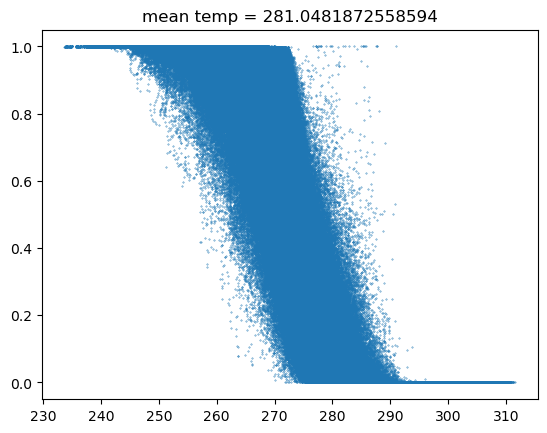

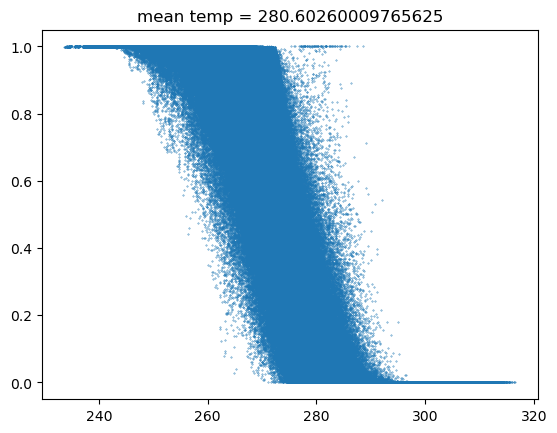

...

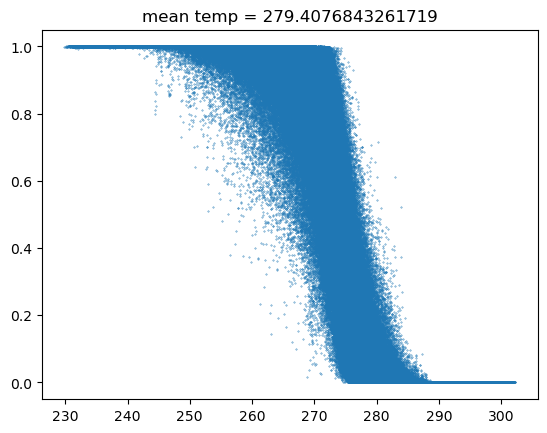

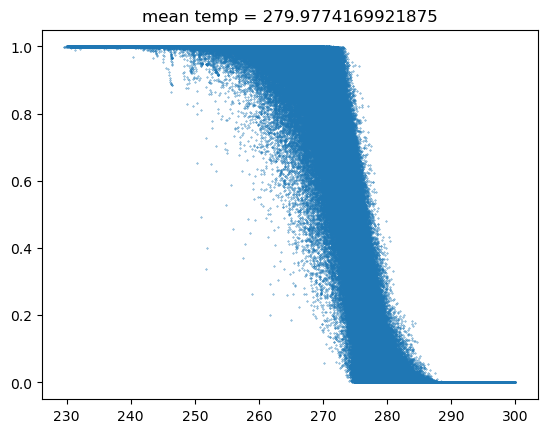

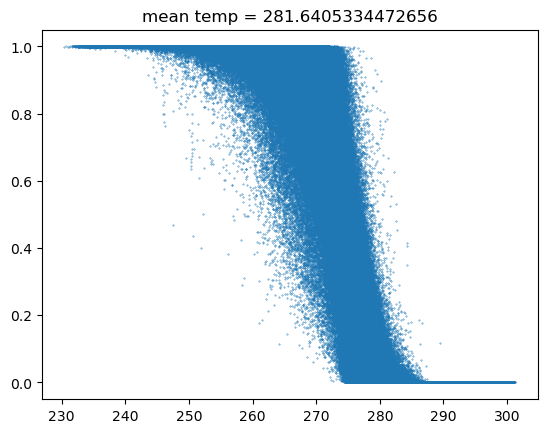

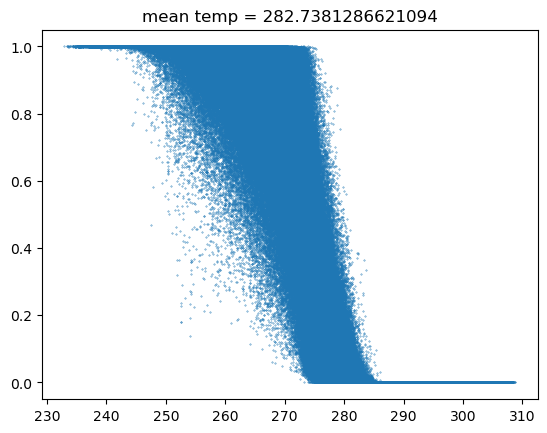

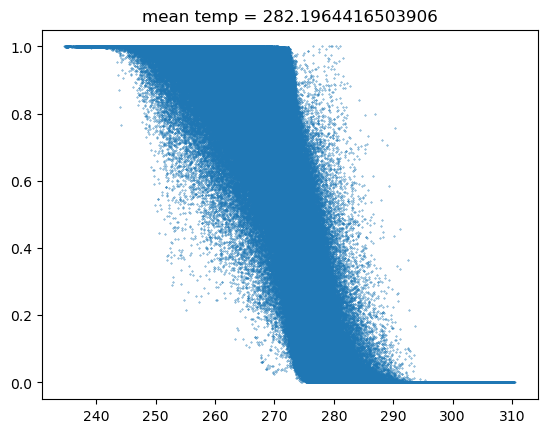

0


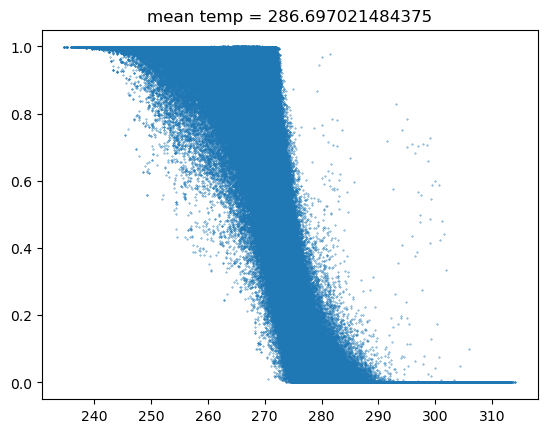

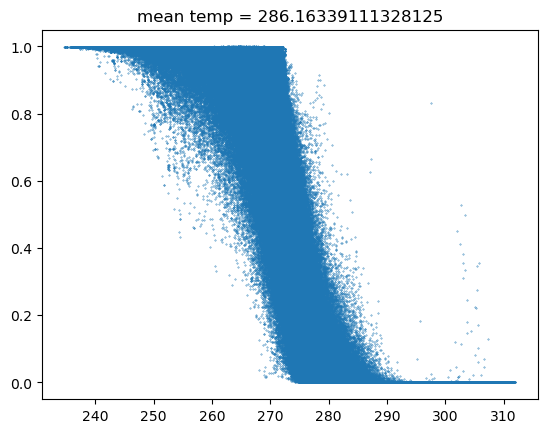

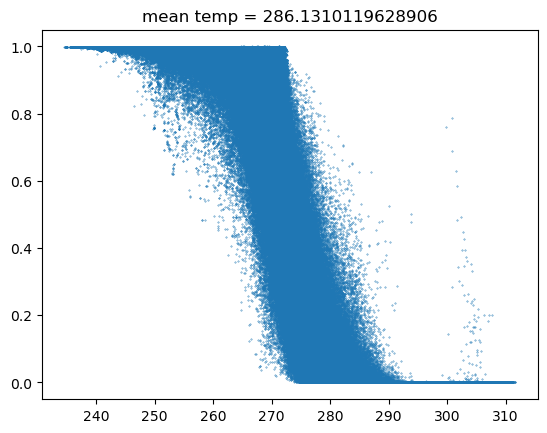

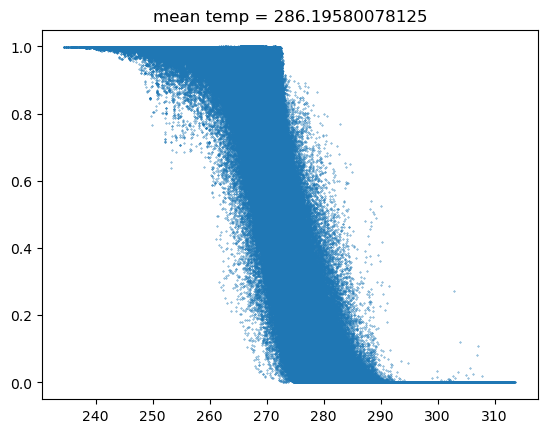

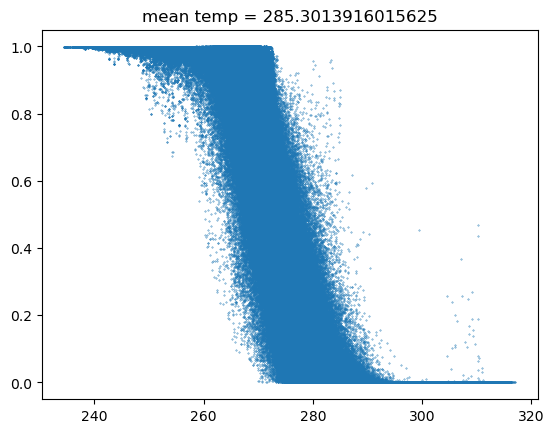

...

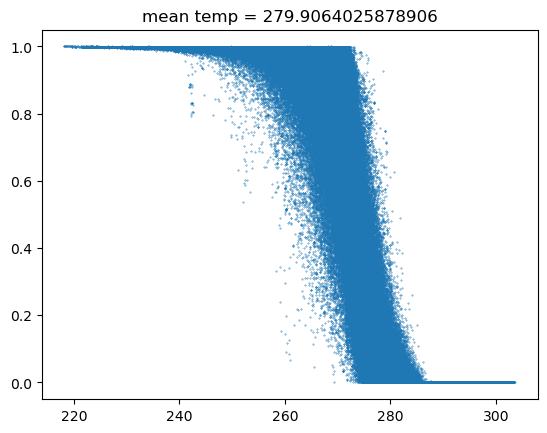

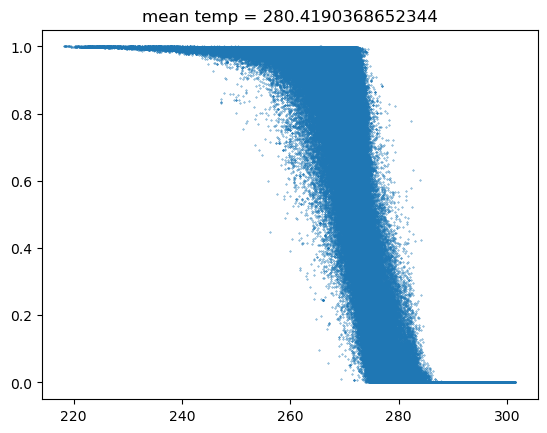

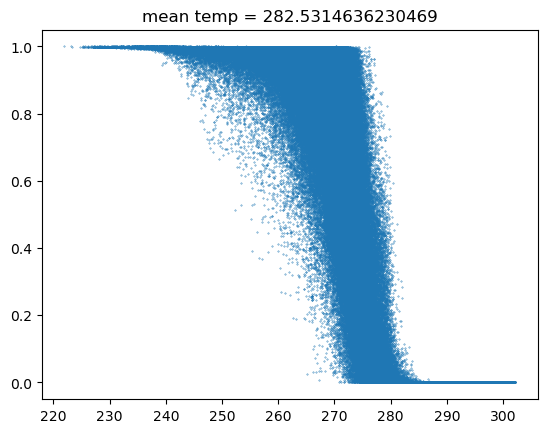

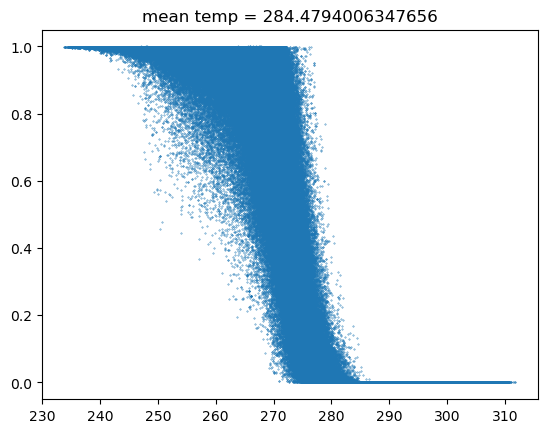

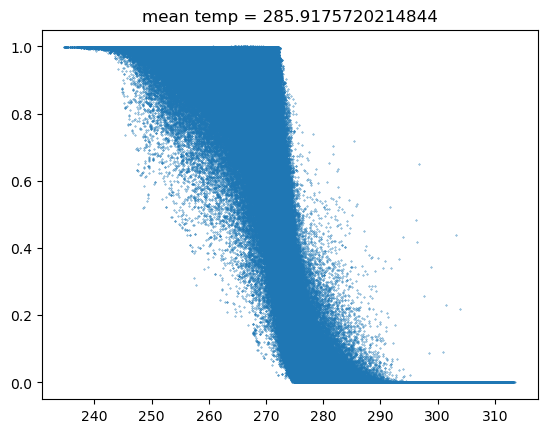

0


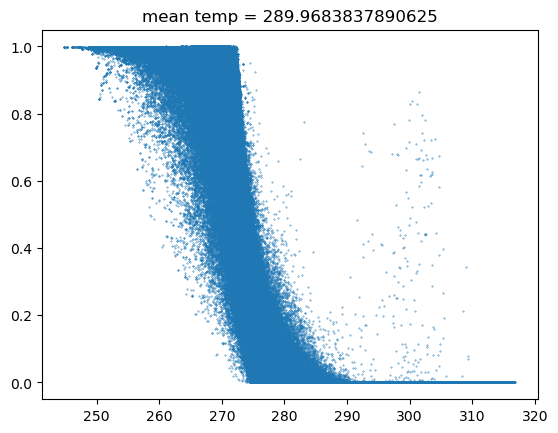

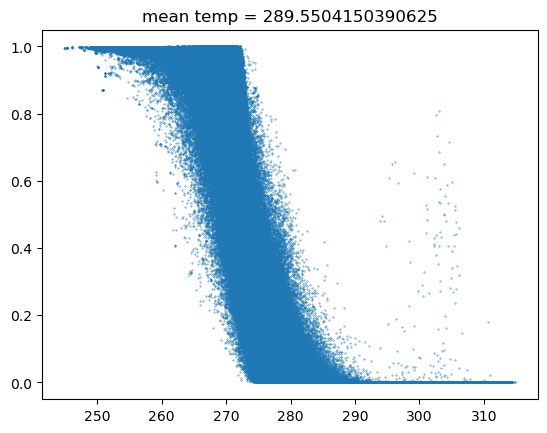

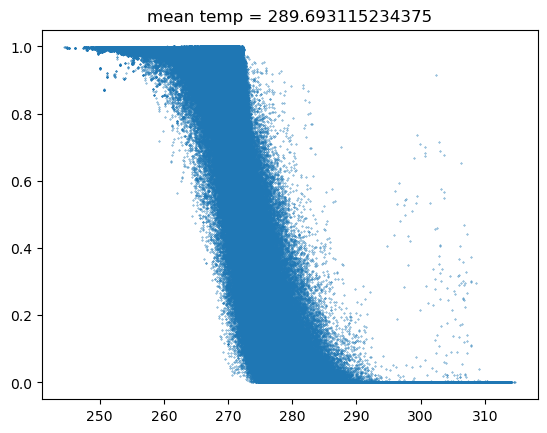

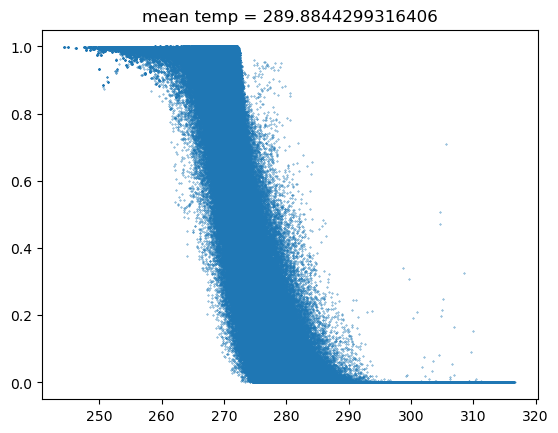

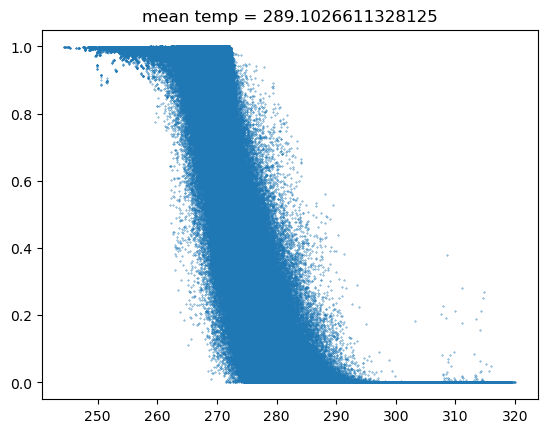

...

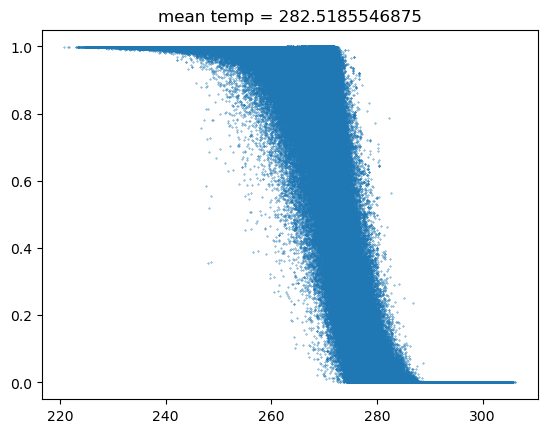

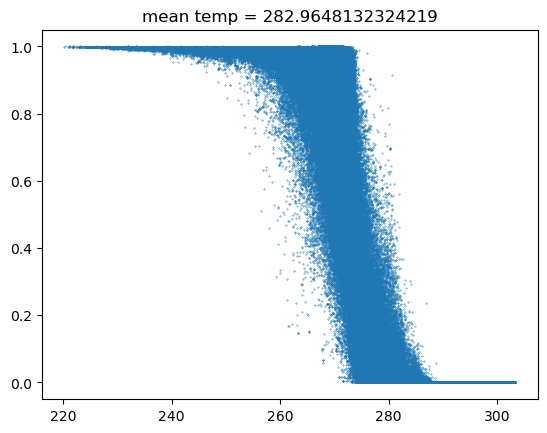

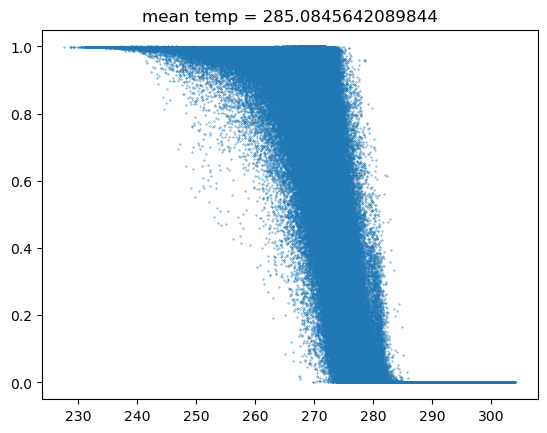

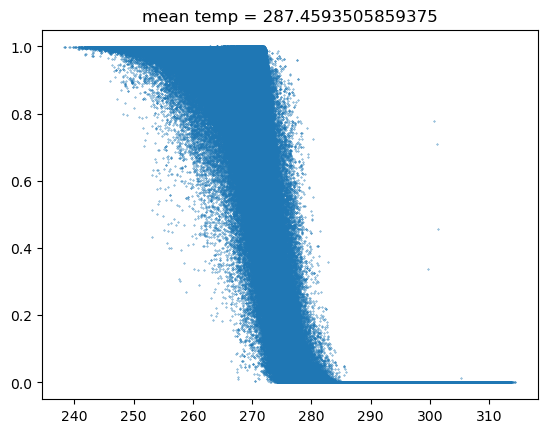

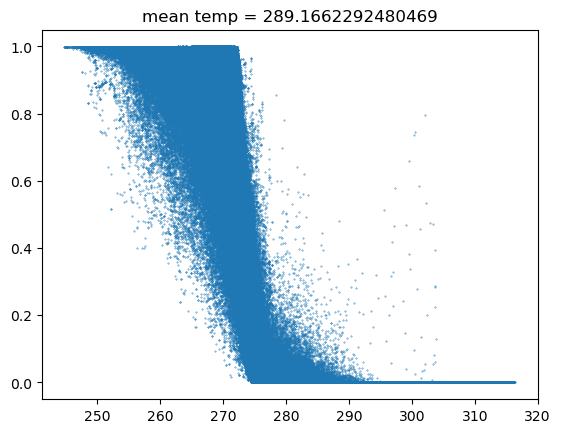

In [126]:
best_a_pi, best_b_pi, mean_temps_pi = fitting_snfr_T(tas_pi, snfr_pi, timestamps_nr = 2)
best_a_2K, best_b_2K, mean_temps_2K = fitting_snfr_T(tas_2K, snfr_2K, timestamps_nr = 2)
best_a_4K, best_b_4K, mean_temps_4K = fitting_snfr_T(tas_4K, snfr_4K, timestamps_nr = 2)
# tas_pi.values

In [41]:

def fitting_snfr_T_area(tas_array, snfr_array, areas, plot=0, min_lat = 0.5, max_lat = 90.5, min_lon = 0, max_lon = 360):
    area_tas = select_area(tas_array, areas, plot=plot, min_lat = min_lat, max_lat = max_lat, min_lon = min_lon, max_lon = max_lon)
    area_snfr = select_area(snfr_array, areas, plot=0, min_lat = min_lat, max_lat = max_lat, min_lon = min_lon, max_lon = max_lon)
         
    tas_1d = area_tas.stack(points=("time","lat","lon"))
    snfr_1d = area_snfr.stack(points=("time","lat", "lon"))

    mask = (~tas_1d.isnull()) & (~snfr_1d.isnull())
    
    tas_1d  = tas_1d.where(mask, drop=True).values
    snfr_1d = snfr_1d.where(mask, drop=True).values 

    try:
        popt, pcov = curve_fit(snowfraction, tas_1d, snfr_1d)
    except RuntimeError:
        # curve_fit failed — skip this iteratiVoor on
        print("Fit failed")

    if plot == 1:
        T = np.linspace(230,310,100)
        plt.figure()
        plt.scatter(tas_1d, snfr_1d, s = 0.1)
        plt.plot(T, snowfraction(T, popt[0], popt[1]), linewidth = 1.2, c = 'red', label = 'Best fit')
        plt.plot(T, snowfraction(T, 1.61, 1.35), linewidth=1, color='orange', label='Krasting et al. 2014', linestyle = '--')
        plt.xlim(265, 282)  
        plt.show()

    return popt[0], popt[1], tas_1d.mean()

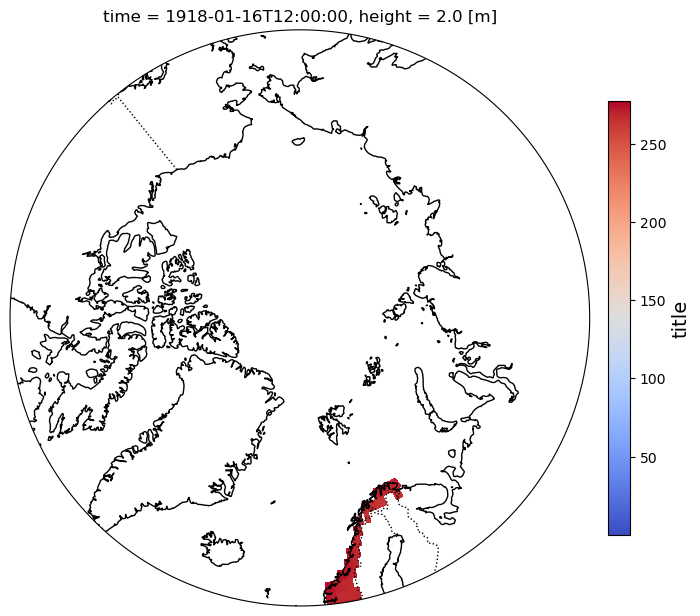

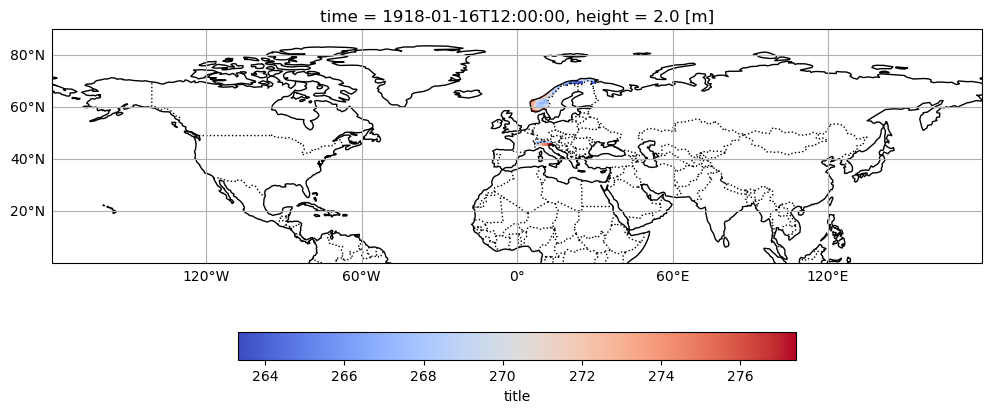

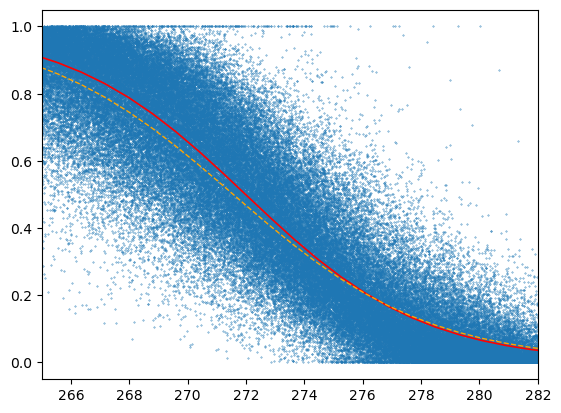

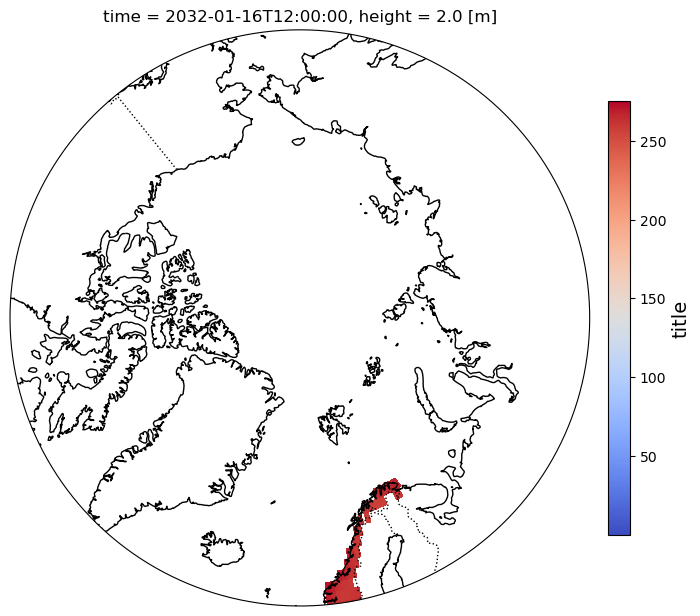

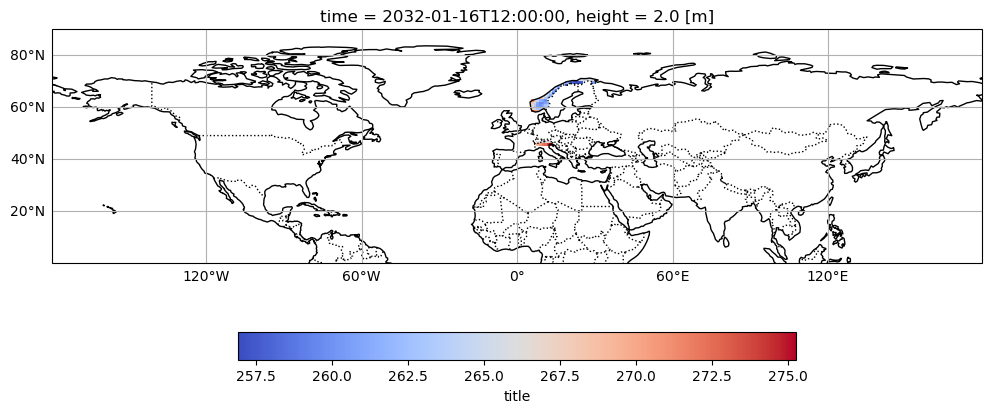

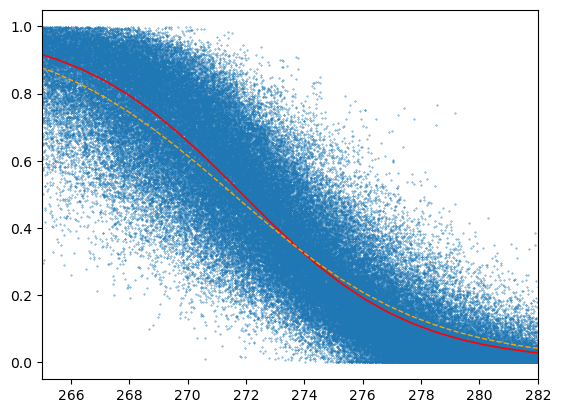

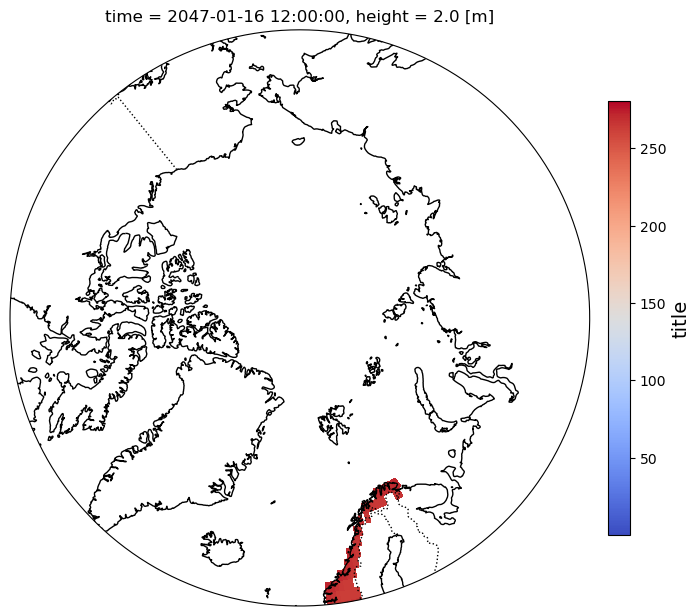

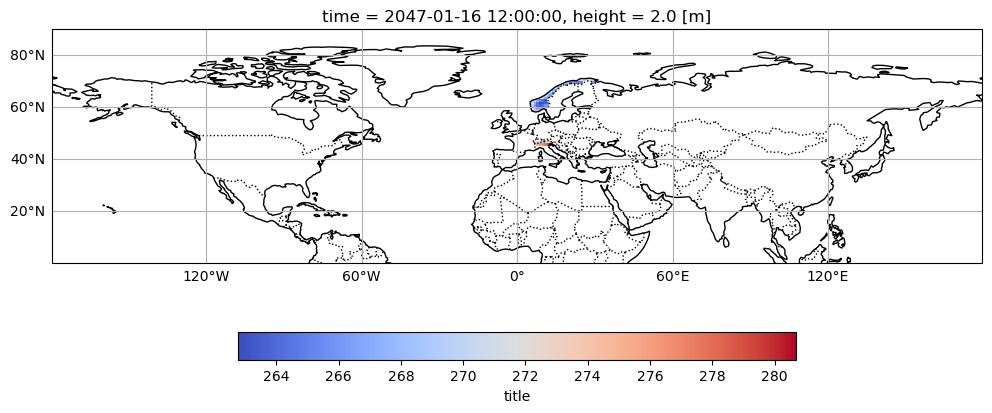

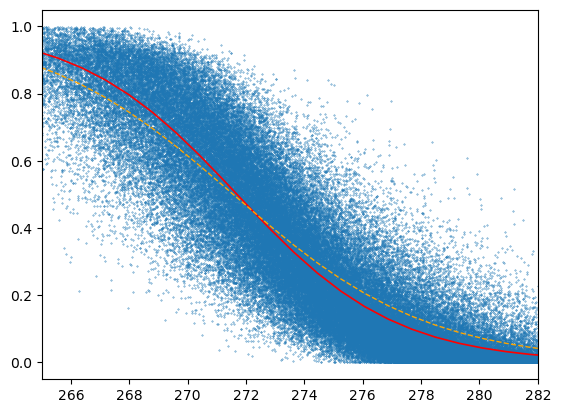

In [45]:
legates_pi_a, legates_pi_b, legates_pi_mean = fitting_snfr_T_area(tas_pi, snfr_pi, ['Norway', ''], plot = 1, min_lat = [0.5, 45], max_lat = [75.5, 47], min_lon = [0, 7], max_lon = [360, 14])
legates_2K_a, legates_2K_b, legates_2K_mean = fitting_snfr_T_area(tas_2K, snfr_2K, ['Norway', ''], plot = 1, min_lat = [0.5, 45], max_lat = [75.5, 47], min_lon = [0, 7], max_lon = [360, 14])
legates_4K_a, legates_4K_b, legates_4K_mean = fitting_snfr_T_area(tas_4K, snfr_4K, ['Norway', ''], plot = 1, min_lat = [0.5, 45], max_lat = [75.5, 47], min_lon = [0, 7], max_lon = [360, 14])

#### Reanalysis data fit

In [39]:
best_a_JRA, best_b_JRA = fitting_snfr_T(JRA_tas, JRA_snfr, 2, 13)
best_a_ERA5, best_b_ERA5 = fitting_snfr_T(ERA5_tas, ERA5_snfr, 2, 13)
best_a_MERRA, best_b_MERRA = fitting_snfr_T(MERRA_tas, MERRA_snfr, 2, 13)

0
0
0


In [34]:
# Fitting RAGMO (separate because of differenct coordinate system)

mask = (~tas_1d_RACMO.isnull()) & (~snfr_1d_RACMO.isnull())

tas_1d_RACMO  = tas_1d_RACMO.where(mask, drop=True).values
snfr_1d_RACMO = snfr_1d_RACMO.where(mask, drop=True).values 

popt, pcov = curve_fit(snowfraction, tas_1d_RACMO, snfr_1d_RACMO)

best_a_RACMO, best_b_RACMO = popt

In [50]:
print(np.mean(best_a_pi), np.mean(best_b_pi))
print(np.mean(best_a_2K), np.mean(best_b_2K))
print(np.mean(best_a_4K), np.mean(best_b_4K))
# print(np.mean(best_a_ERA5), np.mean(best_b_ERA5))
# print(np.mean(best_a_JRA), np.mean(best_b_JRA))
# print(np.mean(best_a_MERRA), np.mean(best_b_MERRA))
# print(best_a_RACMO, best_b_RACMO)

0.5681040591042907 1.920144983579881
0.39424463253560554 1.8084642134190367
0.31839757825943527 1.9758717783074309


### Plotting fits

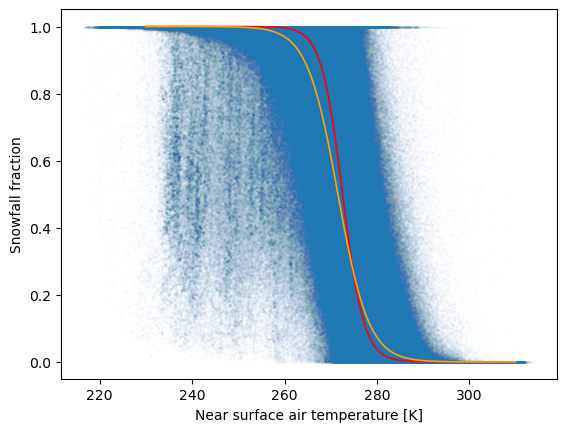

In [50]:
tas_array = tas_pi.isel(time = slice(0,600))
snfr_array = snfr_pi.isel(time = slice(0,600))

tas_snfr_plot(tas_array, snfr_array, savename = '/nobackup/users/hartevel/data/Data_analysis/figures/UKESM_snowfraction_temp_pi_fit.png', best_a = best_a_pi, best_b = best_b_pi) 

# tas_snfr_plot(tas_array, snfr_array, savename = 'snowfraction_temp_pi_fit.png', best_a = 0.6332987332457405, best_b = 1.565550841094958) 

In [ ]:
T = np.linspace(230,310,100)
fig, ax = plt.subplots(1,3, figsize = (15,4), sharey = True)
ax[0].scatter(tas_1d_ERA5, snfr_1d_ERA5, s=1, alpha = 0.01)
ax[0].plot(T, snowfraction(T, np.mean(best_a_ERA5), np.mean(best_b_ERA5)), linewidth = 1.2, c = 'red', label = 'Best fit')
ax[0].plot(T, snowfraction(T, 1.61, 1.35), linewidth = 1.2, c = 'orange', label = 'Krasting et al 2014')
ax[0].set_ylabel("Snowfall fraction")
ax[0].set_xlabel("Near surface air temperature [K]")
ax[0].legend(loc = 'upper right')
ax[0].set_title('ERA 5')

ax[1].scatter(tas_1d_MERRA, snfr_1d_MERRA, s=1, alpha = 0.01)
ax[1].set_xlabel("Near surface air temperature [K]")
ax[1].set_title('MERRA')
ax[1].plot(T, snowfraction(T, np.mean(best_a_MERRA), np.mean(best_b_MERRA)), linewidth = 1.2, c = 'red', label = 'Best fit')
ax[1].plot(T, snowfraction(T, 1.61, 1.35), linewidth = 1.2, c = 'orange', label = 'Krasting et al 2014')
ax[1].legend(loc = 'upper right')

ax[2].scatter(tas_1d_JRA, snfr_1d_JRA, s=1, alpha = 0.01)
ax[2].set_xlabel("Near surface air temperature [K]")
ax[2].set_title('JRA')
ax[2].plot(T, snowfraction(T, np.mean(best_a_JRA), np.mean(best_b_JRA)), linewidth = 1.2, c = 'red', label = 'Best fit')
ax[2].plot(T, snowfraction(T, 1.61, 1.35), linewidth = 1.2, c = 'orange', label = 'Krasting et al 2014')
ax[2].legend(loc = 'upper right')

# plt.xlim(230, 310)  
plt.savefig('snowfraction_temp_ERA5_MERRA_JRA.png')
plt.show()

### plotting the fits

In [127]:
def plot_fits(best_as, best_bs, means, savename='quickplot.png'):
    T = np.linspace(230, 310, 100)
    R = 0.5 - 0.05*(T - 273)

    fig, ax = plt.subplots()

    # --- colormap setup ---
    norm = colors.Normalize(vmin=np.min(means), vmax=np.max(means))
    cmap = cm.viridis

    for a, b, m in zip(best_as, best_bs, means):
        ax.plot(T, snowfraction(T, a, b), alpha=0.6, color=cmap(norm(m)))

    # --- reference curves ---
    ax.plot(T, snowfraction(T, np.mean(best_as), np.mean(best_bs)), linewidth=1, color='red', label='Best fit', linestyle = '--')

    ax.plot(T, snowfraction(T, 1.61, 1.35), linewidth=1, color='orange', label='Krasting et al. 2014', linestyle = '--')
    ax.plot(T, R, linewidth=1, color='orange', label='Krasting et al. 2014', linestyle = '-')

    # --- colorbar ---
    sm = cm.ScalarMappable(norm=norm, cmap=cmap)
    sm.set_array([])
    cbar = fig.colorbar(sm, ax=ax)
    cbar.set_label('Mean temperature [K]')

    ax.set_xlabel("Near surface air temperature [K]")
    ax.set_ylabel("Snowfall fraction")
    ax.set_xlim(255, 290)
    ax.set_ylim(-0.15, 1.15)
    # ax.set_xlim(250, 300)
    ax.legend(loc='upper right')

    fig.savefig(savename, bbox_inches='tight')
    plt.show()

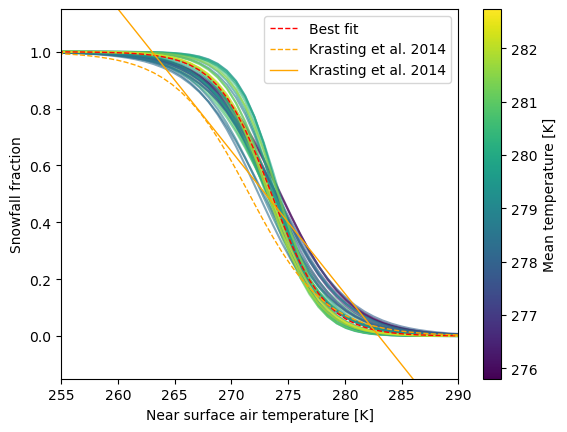

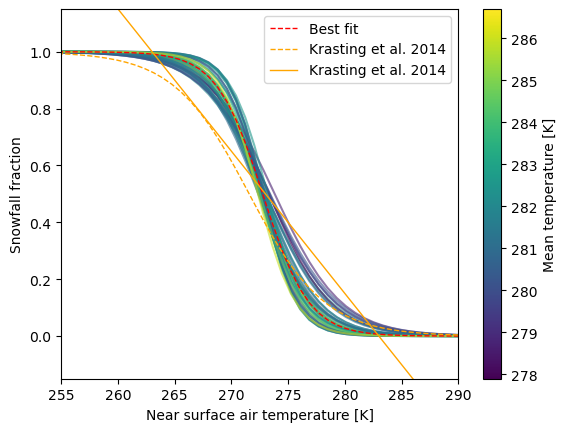

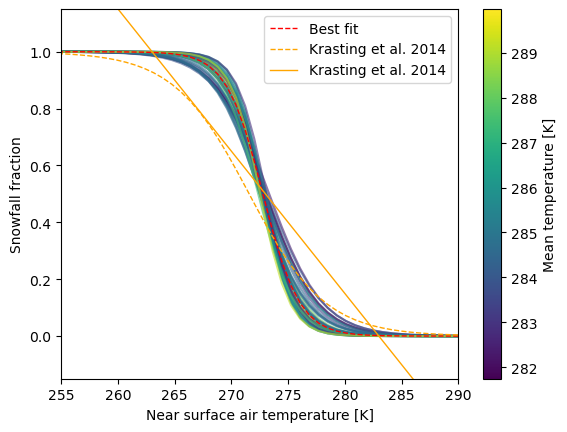

In [128]:
# plot_fits(best_a_pi, best_b_pi, mean_temps_pi, '/nobackup/users/hartevel/data/Data_analysis/figures/EC_earth_snowfraction_pi_fit.png')
# plot_fits(best_a_2K, best_b_2K, mean_temps_2K, '/nobackup/users/hartevel/data/Data_analysis/figures/EC_earth_snowfraction_2K_fit.png')
# plot_fits(best_a_4K, best_b_4K, mean_temps_4K, '/nobackup/users/hartevel/data/Data_analysis/figures/EC_earth_snowfraction_4K_fit.png')

plot_fits(best_a_pi, best_b_pi, mean_temps_pi, '/nobackup/users/hartevel/data/Data_analysis/figures/CNRM_snowfraction_pi_fit.png')
plot_fits(best_a_2K, best_b_2K, mean_temps_2K, '/nobackup/users/hartevel/data/Data_analysis/figures/CNRM_snowfraction_2K_fit.png')
plot_fits(best_a_4K, best_b_4K, mean_temps_4K, '/nobackup/users/hartevel/data/Data_analysis/figures/CNRM_snowfraction_4K_fit.png')


# plot_fits(best_a_ERA5, best_b_ERA5, 'snowfraction_ERA5_fit.png')
# plot_fits(best_a_JRA, best_b_JRA, 'snowfraction_JRA_fit.png')
# plot_fits(best_a_MERRA, best_b_MERRA, 'snowfraction_MERRA_fit.png')

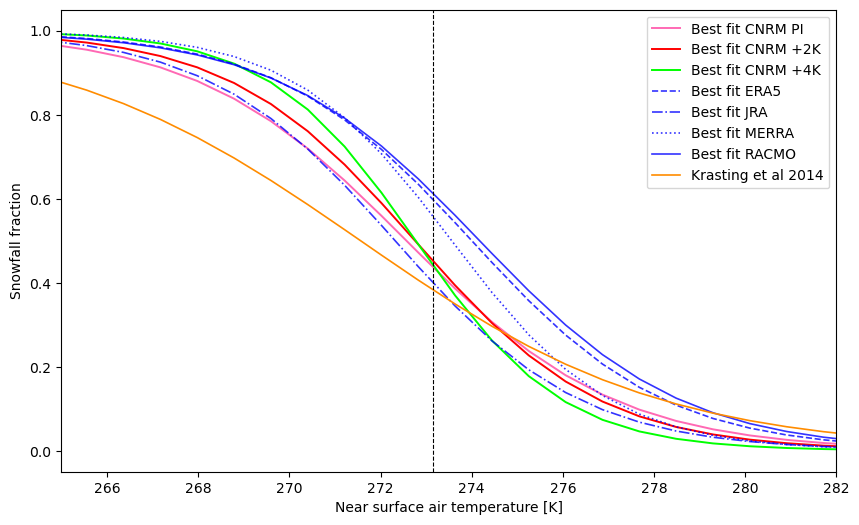

In [74]:
T = np.linspace(230,310,100)
x1, x2 = 265, 280      # temperature range [K]
y1, y2 = 0.2, 0.8     # snowfall fraction range
rect = patches.Rectangle((x1, y1), x2 - x1, y2 - y1, linewidth = 1.2, edgecolor = 'black', facecolor = 'none')

fig, ax = plt.subplots(figsize=(10, 6))

# for i in range(len(best_a_4K)):
    # plt.plot(T, snowfraction(T, best_a[i], best_b[i]), alpha = 0.02, c = 'blue')
    # plt.plot(T, snowfraction(T, best_a_2K[i], best_b_2K[i]), alpha = 0.02, c = 'red')
    # plt.plot(T, snowfraction(T, best_a_4K[i], best_b_4K[i]), alpha = 0.02, c = 'olivedrab')
ax.plot(T, snowfraction(T, np.mean(best_a_pi), np.mean(best_b_pi)), linewidth = 1.4, c = 'hotpink', label = 'Best fit CNRM PI')
ax.plot(T, snowfraction(T, np.mean(best_a_2K), np.mean(best_b_2K)), linewidth = 1.4, c = 'red', label = 'Best fit CNRM +2K')
ax.plot(T, snowfraction(T, np.mean(best_a_4K), np.mean(best_b_4K)), linewidth = 1.4, c = 'lime', label = 'Best fit CNRM +4K')
# ax.plot(T, snowfraction(T, np.mean(best_a_ERA5), np.mean(best_b_ERA5)), linewidth = 1.2, c = 'b', label = 'Best fit ERA5', linestyle = '--', alpha = 0.8)
# ax.plot(T, snowfraction(T, np.mean(best_a_JRA), np.mean(best_b_JRA)), linewidth = 1.2, c = 'b', label = 'Best fit JRA', linestyle = '-.', alpha = 0.8)
# ax.plot(T, snowfraction(T, np.mean(best_a_MERRA), np.mean(best_b_MERRA)), linewidth = 1.2, c = 'b', label = 'Best fit MERRA', linestyle = ':', alpha = 0.8)
# ax.plot(T, snowfraction(T, best_a_RACMO, best_b_RACMO), linewidth = 1.2, c = 'b', label = 'Best fit RACMO', alpha = 0.8)

ax.plot(T, snowfraction(T, 0.67, 1.60), linewidth = 1.2, c = 'b', label = 'Best fit ERA5', linestyle = '--', alpha = 0.8)
ax.plot(T, snowfraction(T, 1.50, 1.63), linewidth = 1.2, c = 'b', label = 'Best fit JRA', linestyle = '-.', alpha = 0.8)
ax.plot(T, snowfraction(T, 0.79, 1.77), linewidth = 1.2, c = 'b', label = 'Best fit MERRA', linestyle = ':', alpha = 0.8)
ax.plot(T, snowfraction(T, 0.63, 1.57), linewidth = 1.2, c = 'b', label = 'Best fit RACMO', alpha = 0.8)
ax.plot(T, snowfraction(T, 1.61, 1.35), linewidth = 1.2, c = 'darkorange', label = 'Krasting et al 2014')

# ax.add_patch(rect)

# axins = inset_axes(
#     ax,
#     width="40%",     # size of inset
#     height="40%",
#     loc="lower left",
#     bbox_to_anchor=(0.05, 0.05, 1, 1),
#     bbox_transform=ax.transAxes
# )

# axins.plot(T, snowfraction(T, np.mean(best_a_pi), np.mean(best_b_pi)), linewidth = 1.4, c = 'hotpink', label = 'Best fit EC-Earth PI')
# axins.plot(T, snowfraction(T, np.mean(best_a_2K), np.mean(best_b_2K)), linewidth = 1.4, c = 'red', label = 'Best fit EC-Earth +2K')
# axins.plot(T, snowfraction(T, np.mean(best_a_4K), np.mean(best_b_4K)), linewidth = 1.4, c = 'lime', label = 'Best fit EC-Earth +4K')
# axins.plot(T, snowfraction(T, 0.67, 1.60), linewidth = 1.2, c = 'b', label = 'Best fit ERA5', linestyle = '--', alpha = 0.8)
# axins.plot(T, snowfraction(T, 1.50, 1.63), linewidth = 1.2, c = 'b', label = 'Best fit JRA', linestyle = '-.', alpha = 0.8)
# axins.plot(T, snowfraction(T, 0.79, 1.77), linewidth = 1.2, c = 'b', label = 'Best fit MERRA', linestyle = ':', alpha = 0.8)
# axins.plot(T, snowfraction(T, 0.63, 1.57), linewidth = 1.2, c = 'b', label = 'Best fit RACMO', alpha = 0.8)
# axins.plot(T, snowfraction(T, 1.61, 1.35), linewidth = 1.2, c = 'darkorange', label = 'Krasting et al 2014')

# axins.set_xlim(x1, x2)
# axins.set_ylim(y1, y2)

# axins.tick_params(labelsize=8)
# axins.grid(True, alpha=0.3)
# mark_inset(ax, axins, loc1=2, loc2=4, fc="none", ec="black", lw=1)


ax.set_xlabel("Near surface air temperature [K]")
ax.set_ylabel("Snowfall fraction")
ax.legend(loc = 'upper right')
ax.axvline(x = 273.15, c = 'black', linewidth = 0.8, linestyle = '--')
ax.set_xlim(265, 282)  
plt.savefig('/nobackup/users/hartevel/data/Data_analysis/figures/CNRM_snowfraction_temp_all_fits.png', bbox_inches = 'tight')
plt.show()

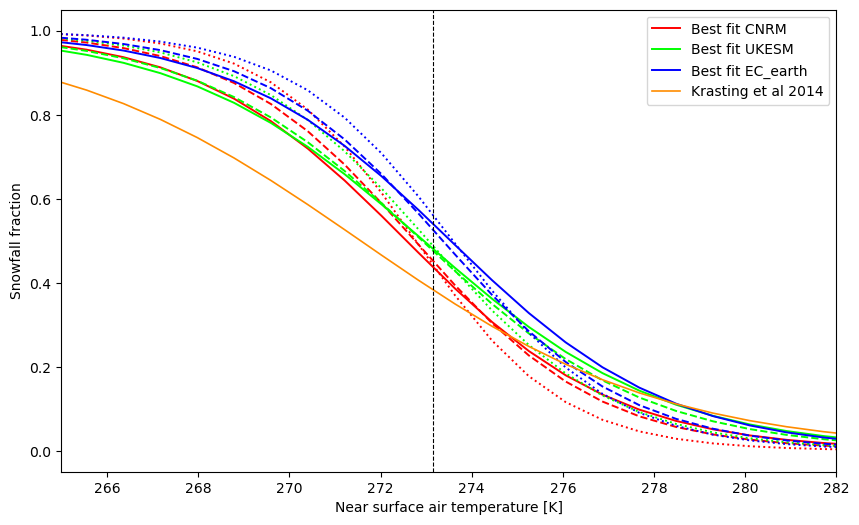

In [72]:
T = np.linspace(230,310,100)

fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(T, snowfraction(T, np.mean(best_a_pi), np.mean(best_b_pi)), linewidth = 1.4, c = 'red', label = 'Best fit CNRM')
ax.plot(T, snowfraction(T, np.mean(best_a_2K), np.mean(best_b_2K)), linewidth = 1.4, c = 'red', linestyle = '--')
ax.plot(T, snowfraction(T, np.mean(best_a_4K), np.mean(best_b_4K)), linewidth = 1.4, c = 'red', linestyle = ':')

ax.plot(T, snowfraction(T, 1.08, 1.46), linewidth = 1.4, c = 'lime', label = 'Best fit UKESM')
ax.plot(T, snowfraction(T, 1.10, 1.50), linewidth = 1.4, c = 'lime', linestyle = '--')
ax.plot(T, snowfraction(T, 1.05, 1.64), linewidth = 1.4, c = 'lime', linestyle = ':' )

ax.plot(T, snowfraction(T, 0.85, 1.52), linewidth = 1.4, c = 'b', label = 'Best fit EC_earth')
ax.plot(T, snowfraction(T, 0.90, 1.63), linewidth = 1.4, c = 'b', linestyle = '--')
ax.plot(T, snowfraction(T, 0.78, 1.76), linewidth = 1.4, c = 'b', linestyle = ':' )


ax.plot(T, snowfraction(T, 1.61, 1.35), linewidth = 1.2, c = 'darkorange', label = 'Krasting et al 2014')


ax.set_xlabel("Near surface air temperature [K]")
ax.set_ylabel("Snowfall fraction")
ax.legend(loc = 'upper right')
ax.axvline(x = 273.15, c = 'black', linewidth = 0.8, linestyle = '--')
ax.set_xlim(265, 282)  
plt.savefig('/nobackup/users/hartevel/data/Data_analysis/figures/ALL_MODELS_snowfraction_temp_fits.png', bbox_inches = 'tight')
plt.show()